In [1]:
from pathlib import Path
from time import perf_counter
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

DATA_DIR = Path(r'D:\Глубокое обучение\Лабораторные работы\Лабораторная работа 2')
SEED = 42
BATCH_SIZE = 128
EPOCHS = 40
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)

Устройство: cuda


## Загрузка и проверка CIFAR-10


In [2]:
train_raw = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=False)
test_raw = datasets.CIFAR10(root=str(DATA_DIR), train=False, download=False)
y_train = np.asarray(train_raw.targets)
y_test = np.asarray(test_raw.targets)
class_names = ['самолёт', 'автомобиль', 'птица', 'кошка', 'олень',
               'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']

assert train_raw.data.shape == (50000, 32, 32, 3)
assert test_raw.data.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000,) and y_test.shape == (10000,)
assert np.array_equal(np.bincount(y_train, minlength=10), np.full(10, 5000))
assert np.array_equal(np.bincount(y_test, minlength=10), np.full(10, 1000))

print('Train:', train_raw.data.shape, 'метки:', y_train.shape)
print('Test: ', test_raw.data.shape, 'метки:', y_test.shape)
print('Одно изображение (H, W, C):', train_raw.data[0].shape)
print(f'Метка первого изображения - {y_train[0]} ({class_names[y_train[0]]})')
print('Яркости:', train_raw.data.dtype, train_raw.data.min(), train_raw.data.max())
print('Классы:', dict(enumerate(class_names)))

Train: (50000, 32, 32, 3) метки: (50000,)
Test:  (10000, 32, 32, 3) метки: (10000,)
Одно изображение (H, W, C): (32, 32, 3)
Метка первого изображения - 6 (лягушка)
Яркости: uint8 0 255
Классы: {0: 'самолёт', 1: 'автомобиль', 2: 'птица', 3: 'кошка', 4: 'олень', 5: 'собака', 6: 'лягушка', 7: 'лошадь', 8: 'корабль', 9: 'грузовик'}


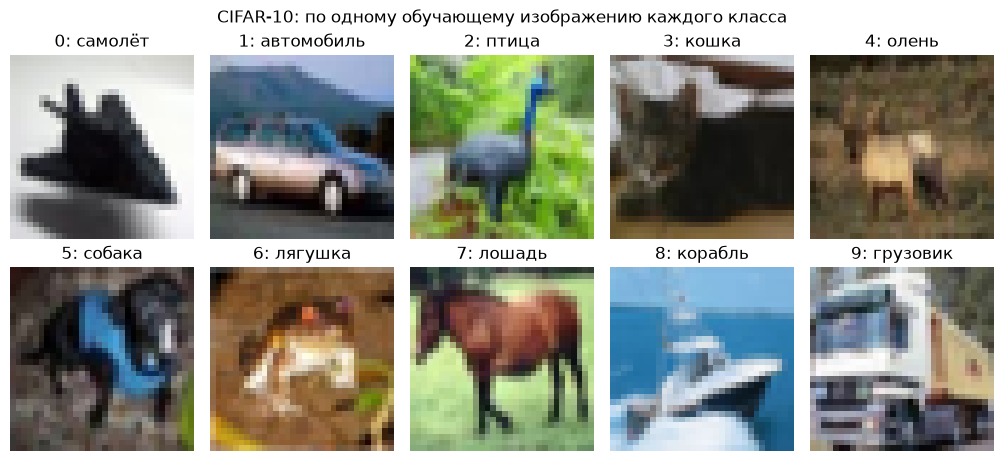

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5), layout='constrained')
for label, ax in enumerate(axes.flat):
    index = np.flatnonzero(y_train == label)[0]
    ax.imshow(train_raw.data[index])
    ax.set_title(f'{label}: {class_names[label]}')
    ax.axis('off')
fig.suptitle('CIFAR-10: по одному обучающему изображению каждого класса')
plt.show()

## Предобработка и мини-батчи


In [4]:
mean = tuple(train_raw.data.mean(axis=(0, 1, 2), dtype=np.float64) / 255.0)
std = tuple(train_raw.data.std(axis=(0, 1, 2), dtype=np.float64) / 255.0)
print('Средние RGB по train:', np.round(mean, 4))
print('Стандартные отклонения RGB по train:', np.round(std, 4))

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_set = datasets.CIFAR10(str(DATA_DIR), train=True, transform=train_transform)
train_eval_set = datasets.CIFAR10(str(DATA_DIR), train=True, transform=eval_transform)
test_set = datasets.CIFAR10(str(DATA_DIR), train=False, transform=eval_transform)

train_eval_loader = DataLoader(train_eval_set, batch_size=256, shuffle=False,
                               num_workers=0, pin_memory=device.type == 'cuda')
test_loader = DataLoader(test_set, batch_size=256, shuffle=False,
                         num_workers=0, pin_memory=device.type == 'cuda')
sample, label = train_eval_set[0]
print('Вход сети (C, H, W):', tuple(sample.shape), sample.dtype)
print('Метка:', label, 'тип:', type(label).__name__)

Средние RGB по train: [0.4914 0.4822 0.4465]
Стандартные отклонения RGB по train: [0.247  0.2435 0.2616]
Вход сети (C, H, W): (3, 32, 32) torch.float32
Метка: 6 тип: int


## Архитектура сети


In [5]:
class CifarCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

## Функция потерь и обучение


In [6]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer):
    model.train()  
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()  
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return {'loss': total_loss / total, 'accuracy': correct / total,
            'error': (total - correct) / total, 'errors': total - correct,
            'total': total}

## Обучение на 40 эпохах


In [7]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


train_loader = DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0, pin_memory=device.type == 'cuda',
)
model = CifarCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE,
                             weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=0.00001,
)
history = []
training_start = perf_counter()
print('Эпоха | Train CE | Ошибка, % | Точность, % | LR       | Время, с', flush=True)
for epoch in range(1, EPOCHS + 1):
    epoch_start = perf_counter()
    lr = optimizer.param_groups[0]['lr']
    train_one_epoch(model, train_loader, optimizer)
    metrics = evaluate(model, train_eval_loader)
    scheduler.step()
    seconds = perf_counter() - epoch_start
    history.append({'epoch': epoch, **metrics,
                    'lr': lr, 'seconds': seconds})
    print(f"{epoch:5d} | {metrics['loss']:8.4f} | {100*metrics['error']:9.2f} | "
          f"{100*metrics['accuracy']:11.2f} | {lr:.6f} | {seconds:8.2f}", flush=True)

training_seconds = perf_counter() - training_start
print(f'Общее время обучения с оценкой train: {training_seconds/60:.2f} мин')

Эпоха | Train CE | Ошибка, % | Точность, % | LR       | Время, с
    1 |   1.1632 |     42.64 |       57.36 | 0.001000 |    19.41
    2 |   1.1149 |     39.48 |       60.52 | 0.000998 |    18.97
    3 |   0.8390 |     29.87 |       70.13 | 0.000994 |    19.67
    4 |   0.6816 |     23.78 |       76.22 | 0.000986 |    19.60
    5 |   0.5963 |     21.02 |       78.98 | 0.000976 |    19.09
    6 |   0.7743 |     24.96 |       75.04 | 0.000962 |    19.84
    7 |   0.5878 |     20.70 |       79.30 | 0.000946 |    20.08
    8 |   0.4598 |     15.81 |       84.19 | 0.000927 |    20.56
    9 |   0.4561 |     15.52 |       84.48 | 0.000905 |    22.14
   10 |   0.4826 |     16.48 |       83.52 | 0.000881 |    20.22
   11 |   0.4175 |     14.07 |       85.93 | 0.000855 |    22.35
   12 |   0.3568 |     12.35 |       87.65 | 0.000826 |    19.71
   13 |   0.3080 |     10.75 |       89.25 | 0.000796 |    18.51
   14 |   0.3385 |     11.82 |       88.18 | 0.000764 |    18.72
   15 |   0.2581 |      9

##  Итоговая оценка на test



In [8]:
test_metrics = evaluate(model, test_loader)
print(f"Кросс-энтропия на test: {test_metrics['loss']:.4f}")
print(f"Ошибка классификации на test: {100*test_metrics['error']:.2f}%")
print(f"Точность на test: {100*test_metrics['accuracy']:.2f}%")
print(f"Неверных ответов: {test_metrics['errors']} из {test_metrics['total']}")

Кросс-энтропия на test: 0.3517
Ошибка классификации на test: 8.65%
Точность на test: 91.35%
Неверных ответов: 865 из 10000


## График ошибки классификации


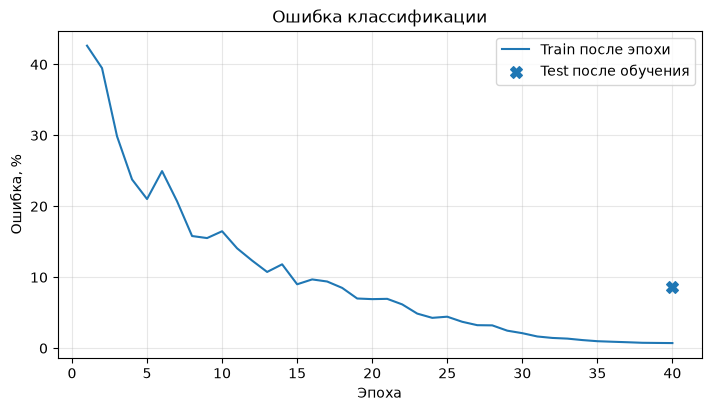

In [9]:
epochs = [row['epoch'] for row in history]
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.plot(epochs, [100 * row['error'] for row in history], label='Train после эпохи')
ax.scatter(epochs[-1], 100 * test_metrics['error'], marker='X', s=70,
           label='Test после обучения', zorder=3)
ax.set(title='Ошибка классификации', xlabel='Эпоха', ylabel='Ошибка, %')
ax.grid(alpha=0.3)
ax.legend()
plt.show()